# Medication Side Effect Explorer

**What do patients and doctors actually report after taking a medication?**

This notebook explores the U.S. FDA Adverse Event Reporting System (**FAERS**), about 20 million reports,
through the free [openFDA API](https://open.fda.gov/apis/drug/event/). It starts from a single raw API request and
ends with a reusable analysis package and a [Gradio web app](../app.py) anyone can use.

**Questions**

1. Which reactions are reported most often for a given drug?
2. Do women's and men's reports differ?
3. How has reporting changed over time?
4. Which reactions are *specific* to a drug, rather than reported for every drug?

> **Read this first.** A FAERS report means someone took a drug and later had a reaction. It does **not** prove
> the drug caused it. Counts depend on how many people take the drug, media attention and reporting habits.
> This is an educational project, **not medical advice**.

## 1. Setup

In [ ]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import requests

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
ASSETS = ROOT / "assets"
ASSETS.mkdir(exist_ok=True)

from med_explorer import analysis, charts
from med_explorer.api import fetch_openfda

pd.set_option("display.max_colwidth", 60)
%matplotlib inline

## 2. A first raw request

openFDA has two useful modes: `search` filters reports, and `count` aggregates a field across the matching
reports. Here we ask: *among reports mentioning ibuprofen, how often does each reaction term appear?*

In [ ]:
url = "https://api.fda.gov/drug/event.json"
params = {
    "search": 'patient.drug.openfda.generic_name:"IBUPROFEN"',
    "count": "patient.reaction.reactionmeddrapt.exact",
    "limit": 10,
}
response = requests.get(url, params=params, timeout=15)
data = response.json()

print("Status:", response.status_code)
print("Keys:", list(data.keys()))
print("Data last updated:", data["meta"]["last_updated"])
data["results"][:3]

Status: 200
Keys: ['meta', 'results']
Data last updated: 2026-07-30


[{'term': 'DRUG INEFFECTIVE', 'count': 27380},
 {'term': 'PAIN', 'count': 19488},
 {'term': 'FATIGUE', 'count': 18754}]

In [ ]:
df = pd.DataFrame(data["results"])
df.columns = ["reaction", "reports"]
df

,reaction,reports
0,DRUG INEFFECTIVE,27380
1,PAIN,19488
2,FATIGUE,18754
3,NAUSEA,18295
4,HEADACHE,16568
5,ARTHRALGIA,13466
6,DYSPNOEA,13139
7,VOMITING,13046
8,DIARRHOEA,12745
9,DIZZINESS,11416


Reactions are coded with **MedDRA** "preferred terms" (hence British spellings like *diarrhoea*). From here on
every request goes through `med_explorer.api.fetch_openfda`, which adds a timeout, turns HTTP errors into
readable messages and caches answers so repeated questions don't spend the rate limit.

## 3. Finding the right drug name

Users type names in many ways: lowercase, with typos, or by brand. The catalog of the most reported generic names
(capped at 500 without an API key) gives us something to match against.

In [ ]:
catalog, _ = analysis.get_drug_catalog()
print(len(catalog), "drugs in the catalog")
catalog.head(10)

500 drugs in the catalog


,drug,reports
0,ADALIMUMAB,703413
1,ETANERCEPT,595127
2,ASPIRIN,534072
3,ASPIRIN 81 MG,508841
4,ASPIRIN 325 MG,508595
5,PREDNISONE,499938
6,METHOTREXATE SODIUM,483131
7,DUPILUMAB,478975
8,ACETAMINOPHEN,445036
9,OMEPRAZOLE MAGNESIUM,436320


A quick search shows the first data-quality issue: the **same molecule appears under several names**.

In [ ]:
catalog[catalog["drug"].str.contains("SERTRALINE|IBUP", regex=True)]

,drug,reports
25,IBUPROFEN,270058
44,IBUPROFEN 200MG,198486
45,IBUPROFEN 200 MG,198429
46,IBUPROFEN CAPSULES 200 MG,198416
47,IBUPROFEN ORAL,198369
48,"IBUPROFEN TABLETS USP, 200MG",198311
49,IBUPFROFEN,198309
50,IBUPROFEN CAPSULE,198307
51,"IBUPROFEN TABLET, FILM COATED",198307
52,"IBUPROFEN TABLET, FILM-COATED",198307


`SERTRALINE` and `SERTRALINE HYDROCHLORIDE` are the same drug. The phrase search
`generic_name:"SERTRALINE"` matches both, so we always search with the **base name**. Brand names are converted
to the generic and salt suffixes are stripped. Typos get `difflib` suggestions:

In [ ]:
inputs = ["sertraline", " Metformin ", "Zoloft", "Tylenol", "ibuprofin", "", "xyzabc"]
rows = []
for text in inputs:
    name, message = analysis.find_drug(text, catalog)
    rows.append({"input": repr(text), "resolved to": name, "message": message})
pd.DataFrame(rows)

,input,resolved to,message
0,'sertraline',SERTRALINE,NaN
1,' Metformin ',METFORMIN,NaN
2,'Zoloft',SERTRALINE,"'ZOLOFT' is a brand name, showing its generic: SERTRALINE."
3,'Tylenol',ACETAMINOPHEN,"'TYLENOL' is a brand name, showing its generic: ACETAMIN..."
4,'ibuprofin',NaN,"'IBUPROFIN' not found. Did you mean: IBUPROFEN, IBUPFROF..."
5,'',NaN,Please type a medication name.
6,'xyzabc',NaN,'XYZABC' was not found in the openFDA database.


Note the suggestion **IBUPFROFEN**, a misspelling that exists *in the FDA data itself*. It has almost exactly
the same report count as nine other ibuprofen variants (about 198k each). openFDA tags each report with the names from
every matching product label, and one label carries the typo. The catalog is a list of label names, not of molecules.

## 4. Most reported reactions

The case study for the rest of the notebook is **sertraline** (Zoloft), one of the most prescribed antidepressants.
`percent` is the share of sertraline reports that mention each reaction (one report can list several).

In [ ]:
DRUG = "SERTRALINE"
total, _ = analysis.count_reports(DRUG)
print(f"{total:,} reports mention {DRUG.lower()}")

top, _ = analysis.get_top_reactions(DRUG, limit=10)
top

218,316 reports mention sertraline


,reaction,reports,percent
0,NAUSEA,13859,6.3
1,DRUG INEFFECTIVE,13621,6.2
2,FATIGUE,12824,5.9
3,HEADACHE,11102,5.1
4,ANXIETY,10372,4.8
5,DIARRHOEA,10340,4.7
6,DIZZINESS,9605,4.4
7,DEPRESSION,9505,4.4
8,OFF LABEL USE,8420,3.9
9,PAIN,8283,3.8


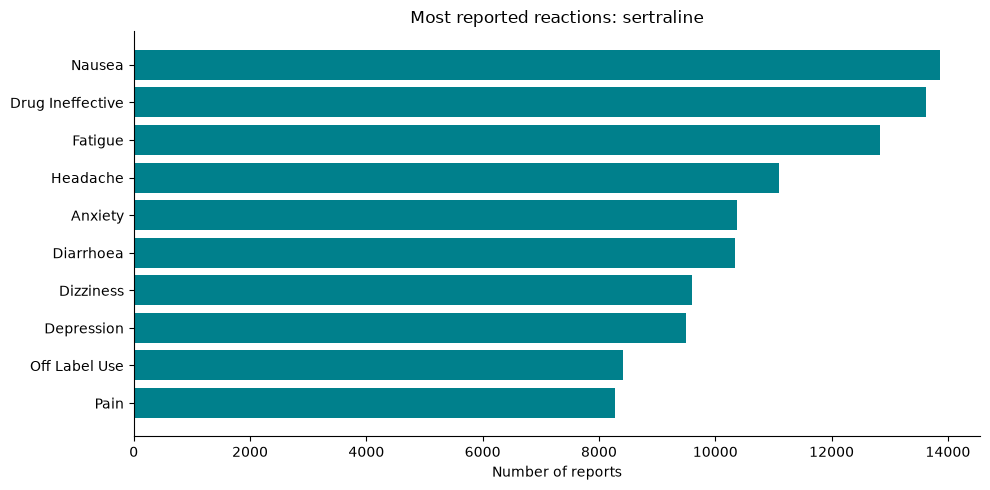

In [ ]:
fig = charts.make_reactions_chart(top, DRUG)
fig.savefig(ASSETS / "top_reactions.png", dpi=120, bbox_inches="tight")
fig

**Observation.** The top of the list (nausea, *drug ineffective*, fatigue, headache) looks like the top of almost
*any* drug's list. Raw counts mostly tell us what people report in general. Section 7 deals with that.

## 5. Women vs men

In [ ]:
by_sex, _ = analysis.get_reports_by_sex(DRUG)
by_sex

,sex,reports,percent
0,Female,134459,67.0
1,Male,65776,32.8
2,Unknown,587,0.3


About two thirds of sertraline reports concern women. That doesn't mean women react more: women are
also prescribed antidepressants about twice as often. So we compare **proportions within each sex**:
the % of women's reports vs the % of men's reports that mention a reaction.

The original version merged each sex's top 10 and left blanks where a reaction was, say, 11th for men.
`compare_by_sex` looks up those values in a deeper list (top 100), so every bar has a real number.

In [ ]:
comparison, _ = analysis.compare_by_sex(DRUG)
comparison

,reaction,percent_women,percent_men,difference
0,NAUSEA,7.3,4.1,3.2
1,DRUG INEFFECTIVE,6.5,5.8,0.7
2,FATIGUE,6.2,5.2,1.0
3,HEADACHE,5.8,3.4,2.4
4,DIARRHOEA,5.0,3.9,1.1
5,ANXIETY,4.9,4.5,0.4
6,DIZZINESS,4.7,3.4,1.3
7,PAIN,4.4,2.9,1.5
8,VOMITING,4.3,2.7,1.6
9,DEPRESSION,4.2,5.0,-0.8


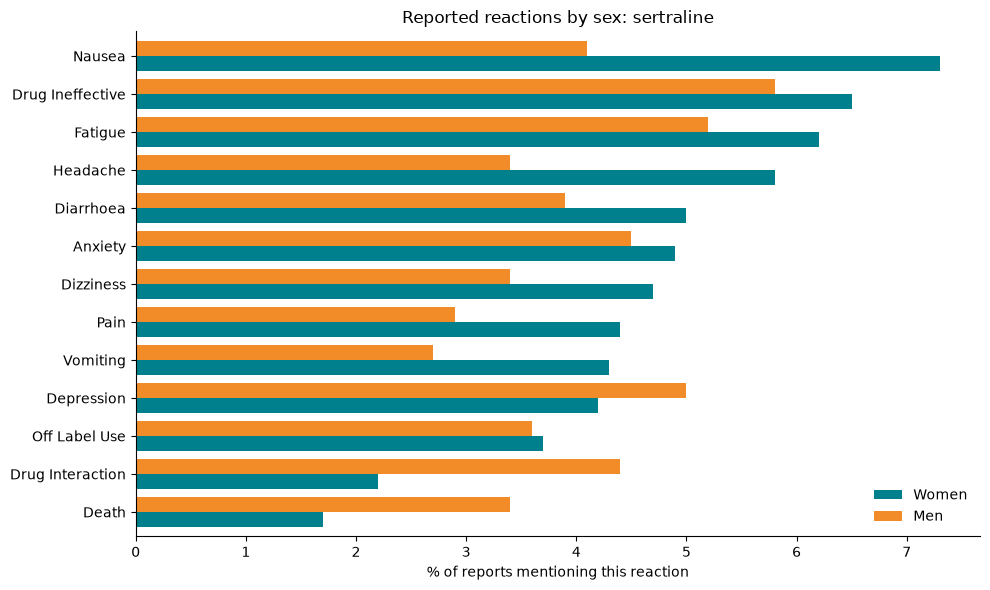

In [ ]:
fig = charts.make_sex_chart(comparison, DRUG)
fig.savefig(ASSETS / "women_vs_men.png", dpi=120, bbox_inches="tight")
fig

## 6. Reports over time

In [ ]:
yearly, _ = analysis.get_yearly_reports(DRUG)
peak = yearly.loc[yearly["reports"].idxmax()]
print(f"Peak year: {int(peak['year'])} with {int(peak['reports']):,} reports")
yearly.tail(8)

Peak year: 2019 with 16,834 reports


,year,reports
14,2018,14810
15,2019,16834
16,2020,15406
17,2021,12916
18,2022,13012
19,2023,11930
20,2024,12835
21,2025,14082


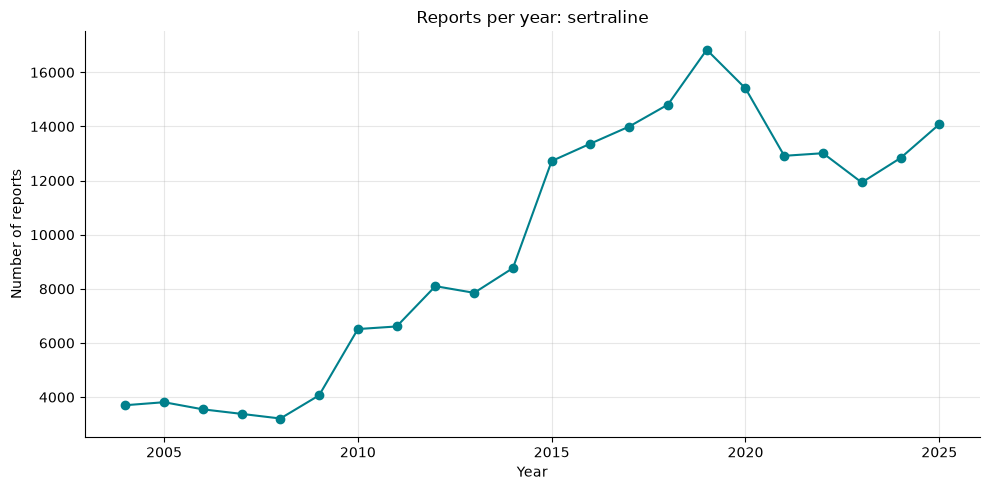

In [ ]:
fig = charts.make_trend_chart(yearly, DRUG)
fig

The current year is excluded because it's incomplete: keeping it would show a fake drop. Here are three SSRIs side by side:

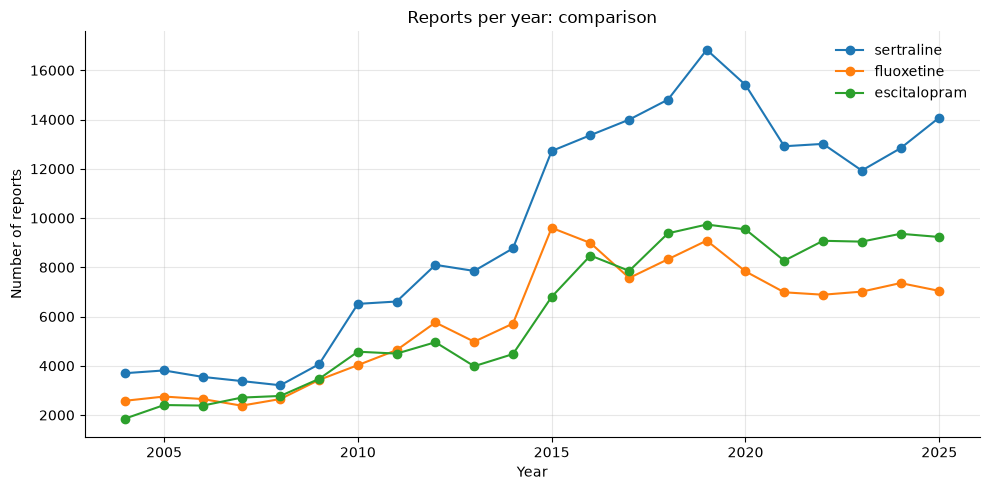

In [ ]:
ssris = ["SERTRALINE", "FLUOXETINE", "ESCITALOPRAM"]
yearly_by_drug = {name: analysis.get_yearly_reports(name)[0] for name in ssris}
fig = charts.make_comparison_chart(yearly_by_drug)
fig.savefig(ASSETS / "ssri_comparison.png", dpi=120, bbox_inches="tight")
fig

**Caution.** These curves track *reporting*, not harm. FAERS volume depends on manufacturer reporting rules,
litigation, news coverage and how many people take the drug, and openFDA has no prescription counts to normalise by.

## 7. Beyond raw counts: which reactions stand out?

To find what's *specific* to a drug, pharmacovigilance teams use **disproportionality analysis**. The simplest
measure is the **proportional reporting ratio (PRR)**:

|                      | reaction R | other reactions |
|----------------------|-----------:|----------------:|
| **drug D**           | a          | b               |
| **all other drugs**  | c          | d               |

$$\mathrm{PRR} = \frac{a / (a+b)}{c / (c+d)}$$

A PRR of 3 means R makes up a three times larger share of D's reports than of other drugs' reports.
A common screening rule flags a **signal** when PRR >= 2, the 95% confidence interval stays above 1,
and there are at least 3 reports. Every number needed comes from openFDA counts: one query for the whole
database's reaction counts (cached), plus per-reaction fallbacks for rare terms.

In [ ]:
signals, _ = analysis.get_reaction_signals(DRUG, limit=50)
print(f"{signals['signal'].sum()} of {len(signals)} top reactions flagged as signals")
signals.head(15)

17 of 50 top reactions flagged as signals


,reaction,reports,percent_drug,percent_others,prr,ci_low,ci_high,signal
0,SUICIDE ATTEMPT,3588,1.64,0.28,5.97,5.77,6.17,True
1,SUICIDAL IDEATION,5136,2.35,0.42,5.65,5.49,5.81,True
2,INTENTIONAL OVERDOSE,3469,1.59,0.29,5.47,5.29,5.66,True
3,DEPRESSION,9505,4.35,1.05,4.13,4.04,4.21,True
4,DRUG INTERACTION,6566,3.01,0.73,4.10,4.01,4.21,True
5,AGITATION,3038,1.39,0.34,4.09,3.95,4.24,True
6,COMPLETED SUICIDE,3396,1.56,0.39,4.00,3.87,4.14,True
7,ANXIETY,10372,4.75,1.32,3.59,3.52,3.66,True
8,TREMOR,5432,2.49,0.77,3.21,3.13,3.30,True
9,CONFUSIONAL STATE,4794,2.20,0.76,2.90,2.82,2.98,True


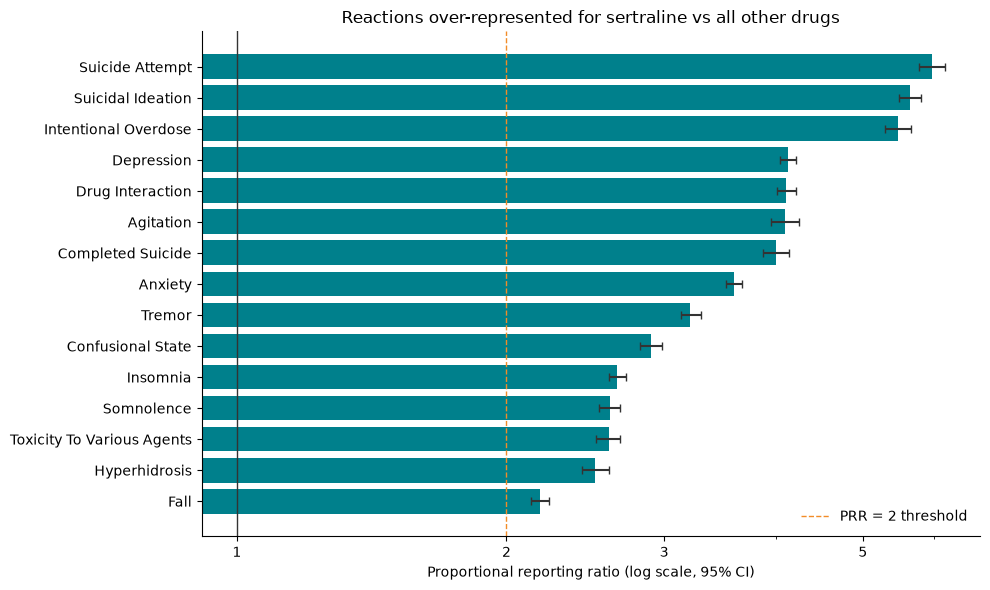

In [ ]:
fig = charts.make_signal_chart(signals, DRUG)
fig.savefig(ASSETS / "signals.png", dpi=120, bbox_inches="tight")
fig

The ranking changes completely. *Drug ineffective* (PRR about 1.0) and *off label use* (about 0.9) are reported no more
often than for any other drug, and nausea, headache and fatigue (PRR 1.6 to 1.7) fall below the threshold.
**Suicide attempt, suicidal ideation, agitation and tremor** rise to the top. These match the known
safety profile of SSRIs, including the FDA boxed warning on suicidality.

### Sanity check on a different drug

If the method works, it should find a well-known drug-specific risk elsewhere too. Metformin's boxed warning is for
**lactic acidosis**:

In [ ]:
metformin, _ = analysis.get_reaction_signals("METFORMIN", limit=50)
metformin[metformin["signal"]].head(8)[["reaction", "reports", "percent_drug", "percent_others", "prr", "ci_low", "ci_high"]]

,reaction,reports,percent_drug,percent_others,prr,ci_low,ci_high
0,LACTIC ACIDOSIS,19399,4.42,0.06,72.91,71.30,74.56
1,METABOLIC ACIDOSIS,6894,1.57,0.12,13.06,12.72,13.41
2,HYPOGLYCAEMIA,8889,2.02,0.19,10.51,10.27,10.75
3,BLOOD GLUCOSE INCREASED,27578,6.28,0.79,8.00,7.90,8.10
4,BLOOD GLUCOSE DECREASED,6886,1.57,0.20,7.81,7.61,8.01
5,ACUTE KIDNEY INJURY,18250,4.16,0.65,6.37,6.28,6.47
6,DIABETES MELLITUS,6241,1.42,0.34,4.15,4.05,4.26
7,WEIGHT DECREASED,17505,3.99,1.27,3.13,3.08,3.18


Lactic acidosis comes out at the top without being told to look for it. This doesn't prove causation (only
controlled studies can), but it shows the PRR separates drug-specific reactions from background noise much better than raw counts.

## 8. Robustness

A public app gets typos, empty boxes and API hiccups. Every analysis function returns `(result, error)` instead of
raising, so the app can show a message instead of a stack trace. The same inputs as above, run through the full pipeline:

In [ ]:
for text in ["sertraline", " Metformin ", "Zoloft", "ibuprofin", "", "xyzabc"]:
    name, message = analysis.find_drug(text, catalog)
    if name is None:
        print(f"{text!r:14} -> {message}")
        continue
    df, error = analysis.get_top_reactions(name, limit=3)
    print(f"{text!r:14} -> {error or 'OK, top reaction: ' + df.iloc[0]['reaction'].lower()}")

'sertraline'   -> OK, top reaction: nausea


' Metformin '  -> OK, top reaction: nausea


'Zoloft'       -> OK, top reaction: nausea


'ibuprofin'    -> 'IBUPROFIN' not found. Did you mean: IBUPROFEN, IBUPFROFEN, BUPROPION, IBUPROFEN ORAL, IBUPROFEN 200MG?
''             -> Please type a medication name.


'xyzabc'       -> 'XYZABC' was not found in the openFDA database.


The same behaviour is covered offline by the test suite (`pytest`), which replaces openFDA with a fake server.

## 9. The app

Everything above is packaged in a Gradio app ([`app.py`](../app.py)): type a medication, get a summary, the top
reactions, the women-vs-men comparison, the trend and the PRR signals. Run it with `python app.py`, or deploy it to
Hugging Face Spaces (see [`deploy/README.md`](../deploy/README.md)).

## 10. What worked, what didn't

**Worked**
- openFDA's `count` queries do the aggregation server-side, so each chart needs one small request and no bulk download.
- Fuzzy matching with `difflib`, plus brand-to-generic lookup, makes the search forgiving.
- The PRR turns a list of "what everyone reports" into drug-specific signals, and recovers known warnings for sertraline and metformin.
- Returning `(result, error)` everywhere kept the app from crashing on bad input.

**Didn't work, or needed fixing**
- The first version had silent bugs: a typo (`yealy`) meant the current-year filter never ran, so every trend ended with a fake drop. Another function was indented inside its error branch and never returned data. Several Colab-only lines (`!pip`, an auto-added import) broke outside Colab.
- openFDA returns a handful of stray records dated before 2004, the year its FAERS data actually starts. They drew a flat line at zero for 1997-2003, so the trend now starts in 2004.
- Naming the script `code.py` shadowed Python's built-in `code` module, and the test runner froze while importing it.
- The women-vs-men merge left blanks for reactions outside one sex's top 10. Fixed by looking values up in a deeper list.
- Searching the brand's exact generic (`SERTRALINE HYDROCHLORIDE`) missed half the reports. Fixed by stripping salt suffixes.
- `count_reports` returned 0 on *any* error, so a network failure looked like "drug not found". 404 now means zero and other errors are reported.
- Without an API key, openFDA rejects `count` limits above 500 and allows 1,000 requests a day per IP, which a shared host can exhaust. Caching and optional `OPENFDA_API_KEY` support address this.

**Limitations**
- Reports aren't causation, and there's no denominator (number of patients taking the drug).
- `generic_name` matches every drug listed in a report, including ones taken alongside it, not just the suspected one.
- Duplicate reports, under-reporting and reporting surges (lawsuits, news coverage) all bias counts.
- The PRR is a screening tool. Real pharmacovigilance adds deduplication, Bayesian shrinkage (e.g. EBGM) and clinical review.

**Next steps**
- Restrict to suspect drugs (`drugcharacterization = 1`) by downloading raw reports instead of using `count`.
- Add age-group breakdowns and serious-outcome filters (death, hospitalisation).
- Normalise trends by prescription volume using an external dataset (e.g. Medicare Part D).